# Исследование рынка стартапов и сделок по их приобретению

## Введение

Финансовая компания, предоставляющая льготные займы стартапам, рассматривает выход на инвестиционный рынок с целью приобретения, развития и последующей перепродажи перспективных компаний. Для формирования инвестиционной стратегии необходимо изучить исторические данные о стартапах, раундах финансирования, сделках по приобретению компаний и их сотрудниках.

Исходные данные содержат пропуски и потенциально аномальные значения, поэтому в рамках исследования особое внимание уделяется оценке качества данных и ограничениям, которые необходимо учитывать при интерпретации результатов.

### Цель исследования

Исследовать исторические данные о стартапах и инвестиционных сделках, определить особенности финансирования и приобретения компаний, а также выявить характеристики, которые могут быть полезны при оценке потенциальных объектов инвестирования.

### Задачи исследования

- оценить качество исходных данных и выполнить необходимую предобработку;
- определить возможности корректного объединения данных из нескольких источников;
- исследовать динамику и особенности раундов финансирования;
- оценить качество данных о сотрудниках стартапов и их образовании;
- проанализировать сделки по приобретению компаний, включая сделки с аномально низкой стоимостью;
- сравнить стоимость приобретения стартапов различных категорий;
- исследовать связь между количеством раундов финансирования, статусом компании и её приобретением;
- сформулировать основные выводы и ограничения проведённого анализа.

### Этапы исследования

**[1. Загрузка и первичный анализ данных](#section-1)**

* [1.1. Изучение структуры данных](#section-1-1)
* [1.2. Проверка типов данных и пропусков](#section-1-2)

**[2. Предобработка и оценка качества данных](#section-2)**

* [2.1. Анализ раундов финансирования](#section-2-1)
* [2.2. Анализ данных о сотрудниках и образовании](#section-2-2)
* [2.3. Определение ключей для объединения данных](#section-2-3)
* [2.4. Анализ причин возникновения пропусков](#section-2-4)

**[3. Исследовательский анализ данных](#section-3)**

* [3.1. Объединение данных о компаниях и сделках](#section-3-1)
* [3.2. Анализ аномальных значений](#section-3-2)
* [3.3. Анализ сделок с нулевой стоимостью](#section-3-3)
* [3.4. Анализ стоимости стартапов по категориям](#section-3-4)
* [3.5. Анализ количества раундов финансирования](#section-3-5)

**[4. Итоговые выводы и рекомендации](#section-4)**

* [Результаты проведенного анализа](#section-4-1)
* [Основные выводы](#section-4-2)
* [Рекомендации](#section-4-3)


### Описание данных
Таблица **`acquisition`** содержит информацию о покупках одними компаниями других компаний:
- `id` — идентификатор покупки.
- `acquiring_company_id` — идентификатор покупающей компании.
- `acquired_company_id` — идентификатор покупаемой компании.
- `term_code` — варианты расчёта.
- `price_amount` — сумма сделки.
- `acquired_at` — дата сделки.
---
Таблица **`company_and_rounds`** содержит информацию о компаниях и раундах финансирования:
- `company ID` — идентификатор компании.
- `name` — название компании.
- `category code` — категория области деятельности компании.
- `status` — статус компании.
- `founded at` — дата инвестирования.
- `closed at` — дата закрытия компании.
- `domain` — официальный сайт компании.
- `network username` — ник компании в сети.
- `country code` — код страны компании.
- `investment rounds` — число инвестиционных раундов.
- `funding rounds` — число раундов финансирования.
- `funding total` — сумма финансирования.
- `milestones` — вехи финансирования.
- `funding round id` — идентификатор этапа финансирования.
- `company id` — идентификатор компании.
- `funded at` — дата финансирования.
- `funding round type` — тип финансирования.
- `raised amount` — сумма финансирования.
- `pre money valuation` — предварительная денежная оценка.
- `participants` — число участников.
- `is first round` — является ли раунд первым.
- `is last round` — является раунд последним.
---
Таблица **`education`** содержит информацию об образовании сотрудника:
- `id` — идентификатор записи об образовании.
- `person_id` — идентификатор работника.
- `instituition` — название учебного заведения.
- `graduated_at` — дата получения образования.
---
Таблица **`people`** содержит информацию о сотрудниках:
- `id` — идентификатор сотрудника.
- `first_name` — имя сотрудника.
- `last_name` — фамилия сотрудника.
- `company_id` — идентификатор компании.
- `network_username` — ник в социальных сетях.
---
Таблица **`degrees`** содержит информацию о типе образования сотрудника:
- `id` — идентификатор записи.
- `object_id` — идентификатор сотрудника.
- `degree_type` — тип образования.
- `subject` — специальность.

---

<a id="section-1"></a>
## 1. Загрузка и первичный анализ данных

Для анализа используются пять датасетов:

- `acquisition.csv` — данные о сделках по приобретению компаний;
- `company_and_rounds.csv` — данные о компаниях и раундах финансирования;
- `people.csv` — данные о сотрудниках компаний;
- `education.csv` — информация об образовании сотрудников;
- `degrees.csv` — данные об образовательных степенях и специальностях.

<a id="section-1-1"></a>
### 1.1. Изучение структуры данных

Загрузим датасеты и посмотрим на их структуру, типы данных, названия столбцов и наличие пропусков.

In [1]:
# Импорт библиотек
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib_venn import venn2
from IPython.display import Markdown, display

In [2]:
# Загрузка данных
path = 'https://code.s3.yandex.net/datasets/'

acquisition = pd.read_csv(path + 'acquisition.csv')
company_and_rounds = pd.read_csv(path + 'company_and_rounds.csv')
people = pd.read_csv(path + 'people.csv')
education = pd.read_csv(path + 'education.csv')
degrees = pd.read_csv(path + 'degrees.csv')

---
#### Датасет **`acquisition`:**

In [3]:
# Выведем первые 5 строк датасета `acquisition`, а также общую информацию о данных
display(Markdown('**Первые 5 строк**'))
display(acquisition.head())

display(Markdown('**Общая информация**'))
acquisition.info()

**Первые 5 строк**

,id,acquiring_company_id,acquired_company_id,term_code,price_amount,acquired_at
0,1,11,10,NaN,20000000,2007-05-30
1,7,59,72,cash,60000000,2007-07-01
2,8,24,132,cash,280000000,2007-05-01
3,9,59,155,cash,100000000,2007-06-01
4,10,212,215,cash,25000000,2007-07-01


**Общая информация**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9407 entries, 0 to 9406
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   id                    9407 non-null   int64 
 1   acquiring_company_id  9407 non-null   int64 
 2   acquired_company_id   9407 non-null   int64 
 3   term_code             1831 non-null   object
 4   price_amount          9407 non-null   int64 
 5   acquired_at           9378 non-null   object
dtypes: int64(4), object(2)
memory usage: 441.1+ KB


---
#### Датасет **`company_and_rounds`:**

In [4]:
# Выведем первые 5 строк датасета `company_and_rounds`, а также общую информацию о данных
display(Markdown('**Первые 5 строк**'))
display(company_and_rounds.head())

display(Markdown('**Общая информация**'))
company_and_rounds.info()

**Первые 5 строк**

,company ID,name,category code,status,founded at,closed at,domain,network username,country code,investment rounds,...,milestones,funding round id,company id,funded at,funding round type,raised amount,pre money valuation,participants,is first round,is last round
0,1.0,Wetpaint,web,operating,2005-10-17,NaN,wetpaint-inc.com,BachelrWetpaint,USA,0.0,...,5.0,888.0,1.0,2005-10-01,series-a,5250000.0,0.0,2.0,0.0,1.0
1,1.0,Wetpaint,web,operating,2005-10-17,NaN,wetpaint-inc.com,BachelrWetpaint,USA,0.0,...,5.0,889.0,1.0,2007-01-01,series-b,9500000.0,0.0,3.0,0.0,0.0
2,1.0,Wetpaint,web,operating,2005-10-17,NaN,wetpaint-inc.com,BachelrWetpaint,USA,0.0,...,5.0,2312.0,1.0,2008-05-19,series-c+,25000000.0,0.0,4.0,1.0,0.0
3,10.0,Flektor,games_video,acquired,NaN,NaN,flektor.com,NaN,USA,0.0,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100.0,There,games_video,acquired,NaN,NaN,there.com,NaN,USA,0.0,...,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Общая информация**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217774 entries, 0 to 217773
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   company  ID            217472 non-null  float64
 1   name                   217472 non-null  object 
 2   category  code         143886 non-null  object 
 3   status                 217472 non-null  object 
 4   founded  at            109956 non-null  object 
 5   closed  at             3449 non-null    object 
 6   domain                 147159 non-null  object 
 7   network  username      95534 non-null   object 
 8   country  code          108607 non-null  object 
 9   investment  rounds     217472 non-null  float64
 10  funding  rounds        217472 non-null  float64
 11  funding  total         217472 non-null  float64
 12  milestones             217472 non-null  float64
 13  funding  round  id     52928 non-null   float64
 14  company  id            52928 non-nul

---
#### Датасет **`people`:**

In [5]:
# Выведем первые 5 строк датасета `people`, а также общую информацию о данных
display(Markdown('**Первые 5 строк**'))
display(people.head())

display(Markdown('**Общая информация**'))
people.info()

**Первые 5 строк**

,id,first_name,last_name,company_id,network_username
0,10,Mark,Zuckerberg,5.0,NaN
1,100,Peter,Lester,27.0,NaN
2,1000,Dr. Steven,E. Saunders,292.0,NaN
3,10000,Neil,Capel,2526.0,NaN
4,100000,Sue,Pilsch,NaN,NaN


**Общая информация**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226709 entries, 0 to 226708
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                226709 non-null  int64  
 1   first_name        226704 non-null  object 
 2   last_name         226708 non-null  object 
 3   company_id        34615 non-null   float64
 4   network_username  38867 non-null   object 
dtypes: float64(1), int64(1), object(3)
memory usage: 8.6+ MB


---
#### Датасет **`education`:**

In [6]:
# Выведем первые 5 строк датасета `education`, а также общую информацию о данных
display(Markdown('**Первые 5 строк**'))
display(education.head())

display(Markdown('**Общая информация**'))
education.info()

**Первые 5 строк**

,id,person_id,instituition,graduated_at
0,1,6117,NaN,NaN
1,2,6136,"Washington University, St. Louis",1990-01-01
2,3,6136,Boston University,1992-01-01
3,4,6005,University of Greenwich,2006-01-01
4,5,5832,Rice University,NaN


**Общая информация**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109610 entries, 0 to 109609
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            109610 non-null  int64 
 1   person_id     109610 non-null  int64 
 2   instituition  109555 non-null  object
 3   graduated_at  58054 non-null   object
dtypes: int64(2), object(2)
memory usage: 3.3+ MB


---
#### Датасет **`degrees`:**

In [7]:
# Выведем первые 5 строк датасета `degrees`, а также общую информацию о данных
display(Markdown('**Первые 5 строк**'))
display(degrees.head())

display(Markdown('**Общая информация**'))
degrees.info()

**Первые 5 строк**

,id,object_id,degree_type,subject
0,1,p:6117,MBA,NaN
1,2,p:6136,BA,"English, French"
2,3,p:6136,MS,Mass Communication
3,4,p:6005,MS,Internet Technology
4,5,p:5832,BCS,"Computer Science, Psychology"


**Общая информация**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109610 entries, 0 to 109609
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   id           109610 non-null  int64 
 1   object_id    109610 non-null  object
 2   degree_type  98392 non-null   object
 3   subject      81298 non-null   object
dtypes: int64(1), object(3)
memory usage: 3.3+ MB


---
#### Информация о датасетах

- **`acquisition`:** содержит 9407 строк и 6 столбцов. Столбец `acquired_at` необходимо привести к типу `datetime64`. Пропуски присутствуют в `term_code` и `acquired_at`.


- **`company_and_rounds`:** содержит 217774 строки и 22 столбца. Названия столбцов необходимо привести к формату snake_case, а `founded at`, `closed at` и `funded at` — к типу `datetime64`. Пропуски присутствуют во всех столбцах.


- **`people`:** содержит 226709 строк и 5 столбцов. Пропуски присутствуют в `first_name`, `last_name`, `company_id` и `network_username`.


- **`education`:** содержит 109610 строк и 4 столбца. Столбец `graduated_at` необходимо привести к типу `datetime64`. Пропуски присутствуют в `instituition` и `graduated_at`.


- **`degrees`:** содержит 109610 строк и 4 столбца. Пропуски присутствуют в `degree_type` и `subject`.

<a id="section-1-2"></a>
### 1.2. Проверка типов данных и пропусков

Приведем столбцы с датами к соответствующему типу данных и оценим количество и долю пропущенных значений в каждом датасете.

---
Обработка **`acquisition`:**

In [8]:
# Понизим размерность числовых типов данных
for column in ['id', 'acquiring_company_id', 'acquired_company_id', 'price_amount']:
    acquisition[column] = pd.to_numeric(acquisition[column], downcast='integer')

# Приведем столбец `acquired_at` к типу `datetime64`
acquisition['acquired_at'] = pd.to_datetime(acquisition['acquired_at'])

In [9]:
# Выведем информацию о пропусках в абсолютных и относительных значениях (%)
acquisition_nan_sum = pd.DataFrame(acquisition.isna().sum())
acquisition_nan_mean = pd.DataFrame(acquisition.isna().mean())
acquisition_nan = acquisition_nan_sum.join(acquisition_nan_mean, lsuffix='sum', rsuffix='mean')
acquisition_nan.columns = ['Кол-во пропусков', 'Доля пропусков (%)']
acquisition_nan['Доля пропусков (%)'] = round(acquisition_nan['Доля пропусков (%)']*100, 4)
acquisition_nan.index.name = 'Столбцы'
acquisition_nan

,Кол-во пропусков,Доля пропусков (%)
Столбцы,,
id,0,0.0000
acquiring_company_id,0,0.0000
acquired_company_id,0,0.0000
term_code,7576,80.5358
price_amount,0,0.0000
acquired_at,29,0.3083


- Понижена размерность числовых типов данных (`id`, `acquiring_company_id`, `acquired_company_id`, `price_amount`).
- Столбец `acquired_at` переведен в формат даты `datetime64`.
- В `term_code` пропущено 7576 значений (80.5%). Столбец не используется в дальнейшем анализе, поэтому заполнять пропуски не будем.
- В `acquired_at` пропущено 29 значений (0.3%). Доля небольшая и не должна существенно повлиять на результаты анализа.

---
Обработка **`company_and_rounds`:**

In [10]:
# Создадим функцию для перевода названий столбов в формат snake_case
def to_snake_case(dataset):
    for column in dataset.columns:
        sk_column = column.split()
        sk_column = '_'.join(sk_column)
        dataset.rename(columns={column: sk_column}, inplace=True)
    return dataset

# Применим функцию к датасету `company_and_rounds`
company_and_rounds = to_snake_case(company_and_rounds)

# Понизим размерность числовых типов данных
for column in ['company_ID', 'investment_rounds', 'funding_rounds', 'funding_total', 
               'milestones', 'funding_round_id', 'company_id', 'raised_amount',
               'pre_money_valuation', 'participants', 'is_first_round', 'is_last_round']:
    company_and_rounds[column] = pd.to_numeric(company_and_rounds[column], downcast='float')
    
# Приведем столбцы `founded_at`, `closed_at` и `funded_at` к типу `datetime64`
for column in ['founded_at', 'closed_at', 'funded_at']:
    company_and_rounds[column] = pd.to_datetime(company_and_rounds[column])

In [11]:
# Выведем информацию о пропусках в абсолютных и относительных значениях (%)
company_and_rounds_nan_sum = pd.DataFrame(company_and_rounds.isna().sum())
company_and_rounds_nan_mean = pd.DataFrame(company_and_rounds.isna().mean())
company_and_rounds_nan = company_and_rounds_nan_sum.join(company_and_rounds_nan_mean, lsuffix='sum', rsuffix='mean')
company_and_rounds_nan.columns = ['Кол-во пропусков', 'Доля пропусков (%)']
company_and_rounds_nan['Доля пропусков (%)'] = round(company_and_rounds_nan['Доля пропусков (%)']*100, 4)
company_and_rounds_nan.index.name = 'Столбцы'
company_and_rounds_nan

,Кол-во пропусков,Доля пропусков (%)
Столбцы,,
company_ID,302,0.1387
name,302,0.1387
category_code,73888,33.9288
status,302,0.1387
founded_at,107818,49.5091
closed_at,214325,98.4162
domain,70615,32.4258
network_username,122240,56.1316
country_code,109167,50.1286


- Названия столбцов приведены к формату snake_case.
- Понижена размерность числовых типов данных.
- Столбцы `founded_at`, `closed_at` и `funded_at` переведены в формат даты `datetime64`.
- В `company_ID`, `name`, `status`, `investment_rounds`, `funding_rounds`, `funding_total` и `milestones` доля пропусков составляет менее 1%.
- В остальных столбцах доля пропусков значительно выше и в отдельных случаях превышает 30%. Удалять или заполнять их на этом этапе не будем, поскольку часть столбцов будет исследована отдельно далее.

Обработка **`people`:**

In [12]:
# Понизим размерность числовых типов данных
people['id'] = pd.to_numeric(people['id'], downcast='integer')
people['company_id'] = pd.to_numeric(people['company_id'], downcast='float')

In [13]:
# Выведем информацию о пропусках в абсолютных и относительных значениях (%)
people_nan_sum = pd.DataFrame(people.isna().sum())
people_nan_mean = pd.DataFrame(people.isna().mean())
people_nan = people_nan_sum.join(people_nan_mean, lsuffix='sum', rsuffix='mean')
people_nan.columns = ['Кол-во пропусков', 'Доля пропусков (%)']
people_nan['Доля пропусков (%)'] = round(people_nan['Доля пропусков (%)']*100, 4)
people_nan.index.name = 'Столбцы'
people_nan

,Кол-во пропусков,Доля пропусков (%)
Столбцы,,
id,0,0.0000
first_name,5,0.0022
last_name,1,0.0004
company_id,192094,84.7315
network_username,187842,82.8560


- Понижена размерность числовых типов данных (`id`, `company_id`).
- Наибольшая доля пропусков наблюдается в `company_id` и `network_username` — более 80%. Эти столбцы будут использоваться в дальнейшем анализе, поэтому неполноту данных необходимо учитывать при интерпретации результатов.
- В `first_name` и `last_name` доля пропусков составляет менее 1%. Эти столбцы не играют существенной роли в дальнейшем исследовании.

---
Обработка **`education`:**

In [14]:
# Понизим размерность числовых типов данных
for column in ['id', 'person_id']:
    education[column] = pd.to_numeric(education[column], downcast='integer')

# Приведем столбец `graduated_at` к типу `datetime64`
education['graduated_at'] = pd.to_datetime(education['graduated_at'])

In [15]:
# Выведем информацию о пропусках в абсолютных и относительных значениях (%)
education_nan_sum = pd.DataFrame(education.isna().sum())
education_nan_mean = pd.DataFrame(education.isna().mean())
education_nan = education_nan_sum.join(education_nan_mean, lsuffix='sum', rsuffix='mean')
education_nan.columns = ['Кол-во пропусков', 'Доля пропусков (%)']
education_nan['Доля пропусков (%)'] = round(education_nan['Доля пропусков (%)']*100, 4)
education_nan.index.name = 'Столбцы'
education_nan

,Кол-во пропусков,Доля пропусков (%)
Столбцы,,
id,0,0.0000
person_id,0,0.0000
instituition,55,0.0502
graduated_at,51556,47.0359


- Понижена размерность числовых типов данных (`id`, `person_id`).
- Столбец `graduated_at` переведен в формат даты `datetime64`.
- В `graduated_at` пропущено 51556 значений (47%). Высокая доля пропусков ограничивает возможности анализа данных об образовании.
- В `instituition` пропущено 55 значений (0.1%), что не является существенной проблемой для дальнейшего анализа.

---
Обработка **`degrees`:**

In [16]:
# Понизим размерность числовых типов данных
degrees['id'] = pd.to_numeric(degrees['id'], downcast='integer')

In [17]:
# Выведем информацию о пропусках в абсолютных и относительных значениях (%)
degrees_nan_sum = pd.DataFrame(degrees.isna().sum())
degrees_nan_mean = pd.DataFrame(degrees.isna().mean())
degrees_nan = degrees_nan_sum.join(degrees_nan_mean, lsuffix='sum', rsuffix='mean')
degrees_nan.columns = ['Кол-во пропусков', 'Доля пропусков (%)']
degrees_nan['Доля пропусков (%)'] = round(degrees_nan['Доля пропусков (%)']*100, 4)
degrees_nan.index.name = 'Столбцы'
degrees_nan

,Кол-во пропусков,Доля пропусков (%)
Столбцы,,
id,0,0.0000
object_id,0,0.0000
degree_type,11218,10.2345
subject,28312,25.8298


- Понижена размерность числового типа данных в столбце `id`.
- В `subject` пропущено 28312 значений (25.8%), в `degree_type` — 11218 (10.2%).
- Заполнить эти пропуски без дополнительных данных нельзя, поэтому оставим их без изменений и учтем неполноту данных при дальнейшем анализе.

#### Итог первичного анализа

Исходных данных достаточно для продолжения исследования, однако их полнота заметно различается между признаками. Основные идентификаторы и финансовые показатели содержат относительно небольшое количество пропусков, тогда как в отдельных столбцах их доля достаточно высокая: например, в `company_id` и `network_username` в датасете `people`, а также в некоторых столбцах с датами.

Особенно внимательно стоит относиться к результатам анализа признаков с большой долей пропусков. Они могут описывать только часть исходной выборки и не всегда быть репрезентативными для всех компаний и сотрудников.

<a id="section-2"></a>
## 2. Предобработка и оценка качества данных

<a id="section-2-1"></a>
### 2.1. Анализ раундов финансирования

Заказчику важно понять, как менялась активность на рынке финансирования стартапов. Рассмотрим динамику количества раундов и типичного размера привлеченных средств по годам.

В качестве типичного значения будем использовать медиану `raised_amount`, так как она менее чувствительна к отдельным крупным инвестициям. В анализ включим годы, в которых было проведено более 50 раундов финансирования.

In [18]:
# Сформируем таблицу с количеством раундов и медианным размером финансирования по годам
car = company_and_rounds[company_and_rounds['funded_at'].notna()].copy()
car['funded_year'] = car['funded_at'].dt.year

car = (car.groupby('funded_year')
    .agg({'raised_amount': 'median',
          'funding_round_id': 'count'}).sort_index())

car['raised_amount'] = car['raised_amount'].astype('int64')
car.columns = ['Типичное финанс. в раунде ($)', 'Кол-во раундов']
car.index.name = 'Год'

# Оставим годы, в которых было проведено более 50 раундов
car = car[car['Кол-во раундов'] > 50]

car

,Типичное финанс. в раунде ($),Кол-во раундов
Год,,
1999,2000000,76
2000,4200000,125
2001,3000000,96
2002,4200000,116
2003,3000000,159
2004,5000000,291
2005,5500000,1633
2006,5000000,2436
2007,3973320,3279


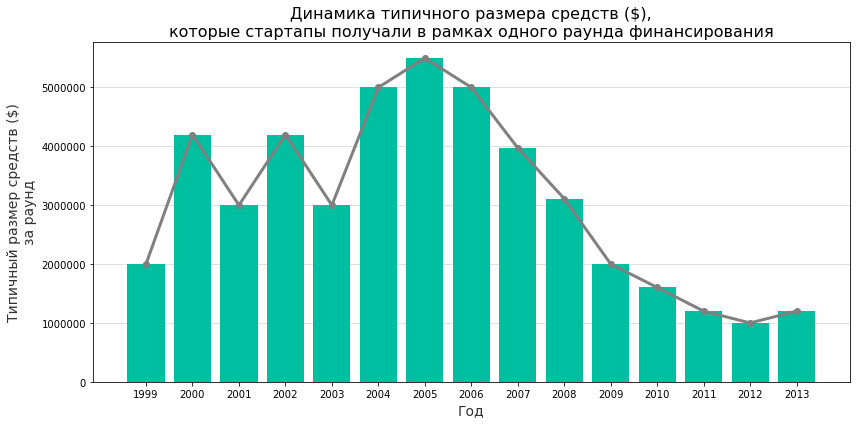

In [19]:
# Построим столбчатую и линейную диаграммы, чтобы отразить динамику типичного размера средств ($) за раунд по годам

plt.figure(figsize=(12, 6))
data = car.reset_index()

# Столбчатая диаграмма
bars = plt.bar(data.index, data['Типичное финанс. в раунде ($)'], 
        color='#00bfa0')

# Линия поверх диаграммы
plt.plot(data.index, data['Типичное финанс. в раунде ($)'], 
         color='grey', linewidth=3, marker='o')

plt.title('Динамика типичного размера средств ($),\nкоторые стартапы получали в рамках одного раунда финансирования', fontsize=16)
plt.xlabel('Год', fontsize=14, alpha=0.8)
plt.ylabel('Типичный размер средств ($)\nза раунд', fontsize=14, alpha=0.8)
plt.xticks(data.index, data['Год'])
plt.grid(axis='y', alpha=0.3, linestyle='-', color='gray')
plt.gca().set_axisbelow(True)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

Максимальный медианный размер финансирования наблюдался в 2005 году и составил 5.5 млн долларов за раунд. После этого показатель постепенно снижался и к 2013 году составил 1.2 млн долларов, то есть уменьшился более чем в 4 раза.

При этом количество раундов, наоборот, росло: с 1999 по 2013 год оно увеличилось с 76 до 11072. Получается, что к концу рассматриваемого периода раундов финансирования стало значительно больше, но типичный объем привлеченных средств в рамках одного раунда снизился.

<a id="section-2-2"></a>
### 2.2. Анализ данных о сотрудниках и образовании

Заказчику также важно оценить качество данных о сотрудниках стартапов. Проверим, различается ли полнота информации об образовании в зависимости от размера компании.

Для этого объединим данные `people` и `education`, разделим компании на группы по количеству сотрудников и сравним долю сотрудников без информации об образовании. Также проверим, дает ли присоединение `degrees` дополнительную информацию.

In [20]:
# Соединим датасеты `people` и `education`
people_edu = pd.merge(
    people,
    education,
    left_on='id',
    right_on='person_id',
    how='left',
    suffixes=('_people', '_education'))

In [21]:
people_edu.head()

,id_people,first_name,last_name,company_id,network_username,id_education,person_id,instituition,graduated_at
0,10,Mark,Zuckerberg,5.0,NaN,2415.0,10.0,Harvard University,NaT
1,100,Peter,Lester,27.0,NaN,NaN,NaN,NaN,NaT
2,1000,Dr. Steven,E. Saunders,292.0,NaN,NaN,NaN,NaN,NaT
3,10000,Neil,Capel,2526.0,NaN,NaN,NaN,NaN,NaT
4,100000,Sue,Pilsch,NaN,NaN,NaN,NaN,NaN,NaT


,Count,Mean,Std,Min,25%,50%,75%,90%,95%,99%,99.9%,Max
Statistics,22922,1.51,2.76,1,1,1,1,2,4,8,23,244


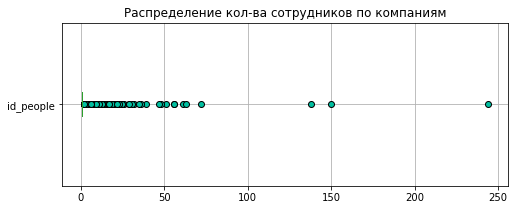

In [22]:
# Посчитаем количество сотрудников в каждой компании
pe = people_edu.groupby('company_id')['id_people'].nunique()

# Посмотрим на распределение количества сотрудников
comp_size_stats = pd.DataFrame({
    'Count': [round(pe.count(), 2)],
    'Mean': [round(pe.mean(), 2)],
    'Std': [round(pe.std(), 2)],
    'Min': [round(pe.min(), 2)],
    '25%': [round(pe.quantile(0.25))],
    '50%': [round(pe.quantile(0.5))],
    '75%': [round(pe.quantile(0.75))],
    '90%': [round(pe.quantile(0.9))],
    '95%': [round(pe.quantile(0.95))],
    '99%': [round(pe.quantile(0.99))],
    '99.9%': [round(pe.quantile(0.999))],
    'Max': [pe.max()]}, index=['Statistics'])

display(comp_size_stats)

# Визуализируем распределение
pd.DataFrame(pe).boxplot(
    vert=False,
    figsize=(8, 3),
    flierprops={'markerfacecolor': '#00bfa0'})
plt.title('Распределение кол-ва сотрудников по компаниям')
plt.show()

In [23]:
# Посмотрим, какую долю составляют компании с небольшим количеством сотрудников
print('Доля компаний по количеству сотрудников (%)')
round(pe.value_counts(normalize=True) * 100, 2).sort_index().head()

Доля компаний по количеству сотрудников (%)


1    79.04
2    11.82
3     4.02
4     1.96
5     1.03
Name: id_people, dtype: float64

Распределение количества сотрудников сильно смещено вправо: около 79% компаний имеют только одного сотрудника, а почти 98% — не более пяти. Компании с несколькими десятками сотрудников встречаются значительно реже.

С учетом распределения выделим пять групп:

- **Микро** — 1 сотрудник;
- **Малые** — 2–5 сотрудников;
- **Растущие** — 6–10 сотрудников;
- **Средние** — 11–50 сотрудников;
- **Крупные** — 51 сотрудник и более.

Компании с одним сотрудником выделены отдельно из-за их высокой доли в выборке. Границы остальных групп позволяют отдельно рассмотреть наиболее распространенные небольшие компании и более редкие компании с большим количеством сотрудников.

In [24]:
# Добавим в объединенный датасет столбец, сигнализирующий об отсутствии информации об образовании сотрудника
people_edu['no_edu_info'] = np.where(
    (people_edu['instituition'].isna()) &
    (people_edu['graduated_at'].isna()),
    True,
    False)

In [25]:
# Сформируем одну запись на каждого сотрудника
employee_edu = (
    people_edu
    .groupby(['company_id', 'id_people'])
    .agg(
        no_edu_info=('no_edu_info', 'all')
    )
    .reset_index()
)

# Посчитаем количество сотрудников и сотрудников без информации об образовании
people_edu_table = (
    employee_edu
    .groupby('company_id')
    .agg(
        Количество_сотрудников=('id_people', 'nunique'),
        Сотрудники_без_информации_об_образовании=('no_edu_info', 'sum')
    )
    .sort_values(by='Количество_сотрудников')
)

# Вернем привычные названия столбцов
people_edu_table.columns = [
    'Количество сотрудников',
    'Сотрудники без информации об образовании'
]

# Разделим компании по размеру
people_edu_table['Вид компании'] = pd.cut(
    people_edu_table['Количество сотрудников'],
    bins=[0, 1, 5, 10, 50, float('inf')],
    labels=[
        'Микро (1)',
        'Малые (2-5)',
        'Растущие (6-10)',
        'Средние (11-50)',
        'Крупные (51+)'
    ]
)

people_edu_table.index.name = 'ID компании'

display(people_edu_table)

,Количество сотрудников,Сотрудники без информации об образовании,Вид компании
ID компании,,,
46.0,1,1,Микро (1)
50.0,1,1,Микро (1)
56.0,1,1,Микро (1)
73.0,1,0,Микро (1)
284549.0,1,0,Микро (1)
...,...,...,...
499.0,63,20,Крупные (51+)
231067.0,72,14,Крупные (51+)
1242.0,138,37,Крупные (51+)


In [26]:
# Рассчитаем долю сотрудников без информации об образовании для каждой группы компаний
people_edu_groups = (
    people_edu_table
    .groupby('Вид компании')[
        ['Количество сотрудников', 'Сотрудники без информации об образовании']]
    .sum())

people_edu_groups['Доля сотрудников без информации об образовании (%)'] = round(
    people_edu_groups['Сотрудники без информации об образовании']
    / people_edu_groups['Количество сотрудников'] * 100, 2)

display(people_edu_groups[['Доля сотрудников без информации об образовании (%)']])

,Доля сотрудников без информации об образовании (%)
Вид компании,
Микро (1),46.27
Малые (2-5),48.02
Растущие (6-10),53.38
Средние (11-50),41.36
Крупные (51+),28.62


Доля сотрудников без информации об образовании различается между группами компаний, но однозначной зависимости от размера компании не наблюдается.

Наибольшая доля отсутствующей информации зафиксирована у растущих компаний (6–10 сотрудников) — 53.38%. Для малых компаний показатель составляет 48.02%, для микрокомпаний — 46.27%, для средних — 41.36%. Наименьшая доля наблюдается у крупных компаний — 28.62%.

Полученные результаты показывают, что данные об образовании сотрудников заполнены неравномерно. Поэтому при дальнейшем использовании этого признака необходимо учитывать неполноту данных во всех группах компаний.

In [27]:
# Добавим информацию о степени и специальности
edu_deg = pd.merge(
    education,
    degrees,
    on='id')

people_edu_deg = pd.merge(
    people,
    edu_deg,
    left_on='id',
    right_on='person_id',
    how='left',
    suffixes=('_people', '_education'))

In [28]:
# Добавим в объединенный датасет столбец, сигнализирующий об отсутствии информации об образовании сотрудника
people_edu_deg['no_edu_info'] = np.where(
    (people_edu_deg['instituition'].isna()) &
    (people_edu_deg['graduated_at'].isna()) &
    (people_edu_deg['degree_type'].isna()) &
    (people_edu_deg['subject'].isna()),
    True,
    False)

In [29]:
# Посчитаем, для скольких сотрудников появилась дополнительная информация
base_no_edu = (
    people_edu
    .groupby('id_people')['no_edu_info']
    .all())

degrees_no_edu = (
    people_edu_deg
    .groupby('id_people')['no_edu_info']
    .all())

edu_comparison = pd.concat(
    [
        base_no_edu.rename('before'),
        degrees_no_edu.rename('after')],
    axis=1)

additional_edu_info = (
    edu_comparison['before']
    & ~edu_comparison['after']).sum()

print(
    'Количество сотрудников, для которых появилась информация '
    f'после присоединения [degrees]: {additional_edu_info}')

Количество сотрудников, для которых появилась информация после присоединения [degrees]: 11


После присоединения `degrees` дополнительная информация появилась только для 11 сотрудников. На общие результаты анализа это практически не влияет, поэтому повторно рассчитывать показатели по группам компаний не будем.

Для дальнейшего анализа достаточно использовать объединение `people` и `education`, а `degrees` может служить дополнительным источником информации о типе образования и специальности.

<a id="section-2-3"></a>
### 2.3. Определение ключей для объединения данных

Проверим, можно ли использовать `network_username` для объединения датасетов `company_and_rounds` и `people`.

Для этого сравним значения столбца в двух таблицах, оценим количество пересечений и проверим наличие дубликатов.

При попытке объединить `company_and_rounds` и `people` по `network_username` возникает ошибка `MemoryError` из-за слишком большого размера результирующей таблицы. Проверим, почему это происходит и подходит ли этот столбец в качестве ключа.

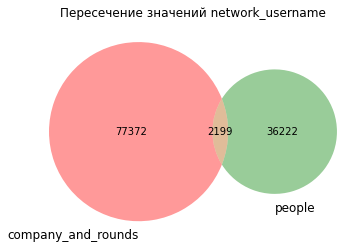

In [30]:
# Сравним уникальные значения `network_username` в двух датасетах
venn2(
    [
        set(company_and_rounds['network_username'].dropna()),
        set(people['network_username'].dropna())
    ],
    set_labels=('company_and_rounds', 'people'))

plt.title('Пересечение значений network_username')
plt.show()

Несмотря на наличие совпадающих значений, `network_username` имеет разный смысл в двух датасетах. В `company_and_rounds` это сетевое имя компании, а в `people` — сетевое имя сотрудника.

Поэтому совпадение значений не означает наличие связи между компанией и человеком. Объединение по этому столбцу может создать случайные и некорректные соответствия.

In [31]:
# Найдем значения `network_username`, которые встречаются в обоих датасетах
both = (
    set(company_and_rounds['network_username'].dropna())
    & set(people['network_username'].dropna()))

# Проверим количество дубликатов среди пересекающихся значений
company_duplicates = company_and_rounds[
    company_and_rounds['network_username'].isin(both)
    & company_and_rounds.duplicated(subset='network_username')
].shape[0]

people_duplicates = people[
    people['network_username'].isin(both)
    & people.duplicated(subset='network_username')
].shape[0]

print(f'Дубликаты network_username в [company_and_rounds]: {company_duplicates}')
print(f'Дубликаты network_username в [people]: {people_duplicates}')

Дубликаты network_username в [company_and_rounds]: 295
Дубликаты network_username в [people]: 71


В обоих датасетах среди пересекающихся значений `network_username` есть дубликаты: 295 в `company_and_rounds` и 71 в `people`.

При объединении таблиц повторяющиеся значения могут приводить к связи «многие ко многим». Если одно значение встречается `M` раз в первой таблице и `N` раз во второй, после объединения для него может появиться `M × N` строк. Это объясняет резкое увеличение размера результирующего датасета и возможное возникновение `MemoryError`.

`network_username` не подходит для объединения `company_and_rounds` и `people`. В двух датасетах этот столбец описывает разные сущности, а совпадения значений не подтверждают связь между компанией и сотрудником.

Дополнительно наличие дубликатов может привести к объединению «многие ко многим» и значительному увеличению количества строк. Поэтому в дальнейшем для связи данных будем использовать идентификаторы компаний и сотрудников.

<a id="section-2-4"></a>
### 2.4. Анализ причин возникновения пропусков

Заказчику важно понять, с чем связано большое количество пропусков в данных о компаниях и раундах финансирования. Для этого подробнее рассмотрим структуру `company_and_rounds`.

В рамках анализа проверим:

- как распределены пропуски между данными о компаниях и раундах финансирования;
- может ли высокая доля пропусков быть связана со структурой исходной таблицы;
- какие данные относятся непосредственно к компаниям, а какие — к отдельным раундам финансирования;
- можно ли разделить исходный датасет на две связанные таблицы `companies` и `rounds`;
- сохраняется ли корректная связь между компаниями и их раундами после разделения.

In [32]:
# Выведем для датасета `company_and_rounds` информацию о столбцах и пропусках в них
company_and_rounds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217774 entries, 0 to 217773
Data columns (total 22 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   company_ID           217472 non-null  float32       
 1   name                 217472 non-null  object        
 2   category_code        143886 non-null  object        
 3   status               217472 non-null  object        
 4   founded_at           109956 non-null  datetime64[ns]
 5   closed_at            3449 non-null    datetime64[ns]
 6   domain               147159 non-null  object        
 7   network_username     95534 non-null   object        
 8   country_code         108607 non-null  object        
 9   investment_rounds    217472 non-null  float32       
 10  funding_rounds       217472 non-null  float32       
 11  funding_total        217472 non-null  float64       
 12  milestones           217472 non-null  float32       
 13  funding_round_

Количество заполненных значений заметно различается между группами столбцов. Характеристики компаний заполнены примерно для 217 тыс. строк, тогда как данные о раундах финансирования присутствуют примерно в 53 тыс. строк.

При этом внутри блока с информацией о раундах количество заполненных значений практически совпадает. Это позволяет предположить, что значительная часть пропусков связана не со случайной потерей отдельных значений, а со структурой исходного датасета.

В одной таблице находятся данные разных уровней: характеристики компании и информация об отдельных раундах ее финансирования. Структура данных позволяет предположить, что строки без информации о раундах соответствуют компаниям, для которых в таблице не зафиксирован отдельный раунд финансирования. Кроме того, при наличии нескольких раундов характеристики одной компании могут повторяться в нескольких строках.

Чтобы проверить эту структуру и сделать данные удобнее для дальнейшего анализа, разделим `company_and_rounds` на таблицы `companies` и `rounds`.

In [33]:
# Выделим данные на уровне компаний
companies = company_and_rounds[
    [
        'company_ID', 'name', 'category_code', 'status',
        'founded_at', 'closed_at', 'domain', 'network_username',
        'country_code', 'investment_rounds', 'funding_rounds',
        'funding_total', 'milestones']].copy()

# Удалим строки без идентификатора компании
companies = companies.dropna(subset=['company_ID'])

# Оставим одну строку для каждой компании
companies = companies.drop_duplicates(subset=['company_ID']).reset_index(drop=True)

# Приведем название ключа к единому виду
companies = companies.rename(columns={'company_ID': 'company_id'})

print('Датасет [companies]')
companies.info()

Датасет [companies]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196553 entries, 0 to 196552
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   company_id         196553 non-null  float32       
 1   name               196553 non-null  object        
 2   category_code      123186 non-null  object        
 3   status             196553 non-null  object        
 4   founded_at         91227 non-null   datetime64[ns]
 5   closed_at          2620 non-null    datetime64[ns]
 6   domain             126545 non-null  object        
 7   network_username   80591 non-null   object        
 8   country_code       87990 non-null   object        
 9   investment_rounds  196553 non-null  float32       
 10  funding_rounds     196553 non-null  float32       
 11  funding_total      196553 non-null  float64       
 12  milestones         196553 non-null  float32       
dtypes: datetime64[ns](2), fl

In [34]:
# Выделим данные на уровне раундов финансирования
rounds = company_and_rounds[
    [
        'funding_round_id', 'company_id', 'funded_at',
        'funding_round_type', 'raised_amount',
        'pre_money_valuation', 'participants',
        'is_first_round', 'is_last_round']].copy()

# Удалим строки, в которых отсутствуют оба идентификатора
rounds = rounds.dropna(
    subset=['funding_round_id', 'company_id'],
    how='all'
).reset_index(drop=True)

print('Датасет [rounds]')
rounds.info()

Датасет [rounds]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52928 entries, 0 to 52927
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   funding_round_id     52928 non-null  float32       
 1   company_id           52928 non-null  float32       
 2   funded_at            52680 non-null  datetime64[ns]
 3   funding_round_type   52928 non-null  object        
 4   raised_amount        52928 non-null  float64       
 5   pre_money_valuation  52928 non-null  float64       
 6   participants         52928 non-null  float32       
 7   is_first_round       52928 non-null  float32       
 8   is_last_round        52928 non-null  float32       
dtypes: datetime64[ns](1), float32(5), float64(2), object(1)
memory usage: 2.6+ MB


In [35]:
# Проверим уникальность идентификаторов и связь между таблицами
print(
    'Дубликаты company_id в companies:',
    companies['company_id'].duplicated().sum())

print(
    'Дубликаты funding_round_id в rounds:',
    rounds['funding_round_id'].duplicated().sum())

rounds_without_company = (
    ~rounds['company_id'].isin(companies['company_id'])).sum()

print(
    'Раунды без соответствующей компании:',
    rounds_without_company)

Дубликаты company_id в companies: 0
Дубликаты funding_round_id в rounds: 0
Раунды без соответствующей компании: 302


После разделения исходного датасета получили две таблицы разных уровней: `companies` содержит одну строку на компанию, а `rounds` — одну строку на раунд финансирования. Дубликатов идентификаторов компаний и раундов не обнаружено.

При проверке связности данных выявлено 302 раунда, для которых соответствующая компания отсутствует в `companies`. Это небольшая часть от 52 928 раундов, однако такие записи необходимо учитывать при дальнейшем объединении таблиц.

Анализ также показал, что большое количество пропусков в исходном `company_and_rounds` во многом связано с его структурой: данные о компаниях и отдельных раундах финансирования хранятся в одной таблице, поэтому информация о раундах заполнена только для части строк. Разделение данных на `companies` и `rounds` позволяет работать с каждым уровнем отдельно и не воспринимать такие структурные пропуски как обычные пропущенные значения.

<a id="section-3"></a>
## 3. Исследовательский анализ данных

<a id="section-3-1"></a>
### 3.1. Объединение данных о компаниях и сделках

Заказчика прежде всего интересуют компании, которые меняли владельцев или потенциально могут представлять интерес с точки зрения сделок. В рамках исследования будем считать получение финансирования или участие в инвестициях одним из признаков такого интереса.

Для дальнейшего анализа отберем компании, которые соответствуют хотя бы одному из условий:

- количество раундов финансирования `funding_rounds` больше нуля;
- количество инвестиционных раундов `investment_rounds` больше нуля;
- статус компании — `acquired`.

После отбора объединим данные о компаниях с информацией о сделках из `acquisition` и проверим получившийся датасет.

In [36]:
# Отберем компании, соответствующие условиям дальнейшего анализа
companies_filtered = companies[
    (companies['funding_rounds'] > 0)
    | (companies['investment_rounds'] > 0)
    | (companies['status'] == 'acquired')].copy()

# Добавим информацию о сделках
companies_acquisition = pd.merge(
    companies_filtered,
    acquisition,
    left_on='company_id',
    right_on='acquired_company_id',
    how='left')

display(companies_acquisition.head())

print(
    f'Количество строк в companies_acquisition: '
    f'{companies_acquisition.shape[0]}')

,company_id,name,category_code,status,founded_at,closed_at,domain,network_username,country_code,investment_rounds,funding_rounds,funding_total,milestones,id,acquiring_company_id,acquired_company_id,term_code,price_amount,acquired_at
0,1.0,Wetpaint,web,operating,2005-10-17,NaT,wetpaint-inc.com,BachelrWetpaint,USA,0.0,3.0,39750000.0,5.0,NaN,NaN,NaN,NaN,NaN,NaT
1,10.0,Flektor,games_video,acquired,NaT,NaT,flektor.com,NaN,USA,0.0,0.0,0.0,0.0,1.0,11.0,10.0,NaN,20000000.0,2007-05-30
2,100.0,There,games_video,acquired,NaT,NaT,there.com,NaN,USA,0.0,0.0,0.0,4.0,20.0,377.0,100.0,cash,0.0,2005-05-29
3,1001.0,FriendFeed,web,acquired,2007-10-01,NaT,friendfeed.com,friendfeed,USA,0.0,1.0,5000000.0,3.0,1901.0,5.0,1001.0,cash_and_stock,47500000.0,2009-08-10
4,10014.0,Mobclix,mobile,acquired,2008-03-01,NaT,mobclix.com,mobclix,USA,0.0,1.0,0.0,4.0,3878.0,23054.0,10014.0,NaN,0.0,2010-09-30


Количество строк в companies_acquisition: 40890


In [37]:
# Проверим размер и основные характеристики получившейся таблицы
print(f'Количество строк: {companies_acquisition.shape[0]}')
print(f'Количество столбцов: {companies_acquisition.shape[1]}')
print(f'Уникальных компаний: {companies_acquisition["company_id"].nunique()}')
print(f'Полных дубликатов: {companies_acquisition.duplicated().sum()}')

# Проверим долю пропусков
missing_share = (
    companies_acquisition
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False))

display(missing_share.to_frame('Доля пропусков (%)'))

# Проверим, сколько компаний встречается в таблице более одного раза
repeated_companies = (
    companies_acquisition['company_id']
    .value_counts()
    .gt(1)
    .sum()
)

print(f'Компаний с несколькими строками: {repeated_companies}')

Количество строк: 40890
Количество столбцов: 19
Уникальных компаний: 40747
Полных дубликатов: 0


,Доля пропусков (%)
term_code,95.524578
closed_at,94.795794
acquired_at,77.106872
id,77.035950
acquired_company_id,77.035950
price_amount,77.035950
acquiring_company_id,77.035950
network_username,48.794326
founded_at,31.741257
country_code,14.751773


Компаний с несколькими строками: 127


После отбора и объединения получили 40 890 строк для 40 747 уникальных компаний. Полных дубликатов в таблице нет. При этом 127 компаний встречаются более одного раза, поскольку для них в `acquisition` содержится несколько записей о сделках.

Основные признаки компаний (`company_id`, `name`, `status`, `funding_rounds`, `investment_rounds`, `funding_total`, `milestones`) заполнены полностью. Высокая доля пропусков в полях из `acquisition` ожидаема, поскольку данные о сделках есть только для части отобранных компаний. Например, `price_amount` и идентификаторы участников сделки отсутствуют примерно в 77% строк.

Полученный датасет подходит для дальнейшего анализа. При работе с показателями сделок будем учитывать, что информация о них доступна только для части компаний.

<a id="section-3-2"></a>
### 3.2. Анализ аномальных значений

Заказчика интересует типичный для рассматриваемого периода объем финансирования одной компании. Для его оценки исследуем распределение `funding_total` и определим, какие значения можно считать типичными, а какие заметно выбиваются из общего распределения.

Сначала рассмотрим основные статистики и распределение показателя, а затем оценим границу выбросов с помощью межквартильного размаха.

Выведем информацию о статистиках для оценки распределения размера общего финансирования ($) `funding_total` на одну компанию, чтобы выявить типичные и аномальные значения. Для наглядности построим ящик с усами для оценки удаленности выбросов.

,Count,Mean,Std,Min,25%,50%,75%,90%,95%,99%,99.9%,Max
Statistics,40890,10135586,56412887,0,0,600000,5631320,22391020,43600000,134203880,562777500,5700000000


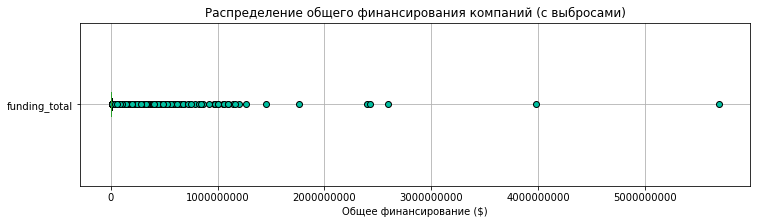

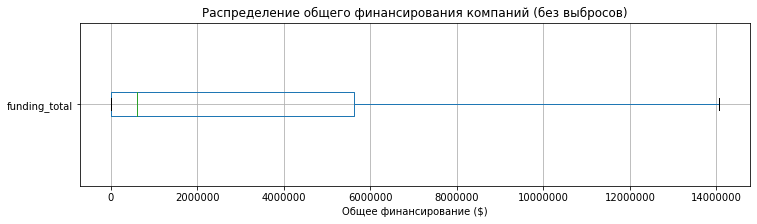

In [38]:
# Настроим отображение больших чисел
pd.set_option('display.float_format', '{:.0f}'.format)

# Рассчитаем основные статистики общего финансирования на одну компанию
ca_values = companies_acquisition['funding_total']

companies_funding_stats = pd.DataFrame({
    'Count': [ca_values.count()],
    'Mean': [ca_values.mean()],
    'Std': [ca_values.std()],
    'Min': [ca_values.min()],
    '25%': [ca_values.quantile(0.25)],
    '50%': [ca_values.quantile(0.5)],
    '75%': [ca_values.quantile(0.75)],
    '90%': [ca_values.quantile(0.9)],
    '95%': [ca_values.quantile(0.95)],
    '99%': [ca_values.quantile(0.99)],
    '99.9%': [ca_values.quantile(0.999)],
    'Max': [ca_values.max()]
}, index=['Statistics'])

display(companies_funding_stats)

# Посмотрим на распределение с выбросами
pd.DataFrame(ca_values).boxplot(
    vert=False,
    figsize=(12, 3),
    flierprops={'markerfacecolor': '#00bfa0'}
)
plt.title('Распределение общего финансирования компаний (с выбросами)')
plt.ticklabel_format(axis='x', style='plain', useOffset=False)
plt.xlabel('Общее финансирование ($)')
plt.show()

# Посмотрим на распределение без отображения выбросов
pd.DataFrame(ca_values).boxplot(
    vert=False,
    figsize=(12, 3),
    showfliers=False
)
plt.title('Распределение общего финансирования компаний (без выбросов)')
plt.ticklabel_format(axis='x', style='plain', useOffset=False)
plt.xlabel('Общее финансирование ($)')
plt.show()

Распределение `funding_total` имеет выраженный правый хвост. Медианное финансирование составляет 600 тыс. долларов, тогда как среднее превышает 10 млн долларов и примерно в 17 раз больше медианы. Максимальное значение достигает 5.7 млрд долларов.

Из-за крупных значений среднее плохо описывает типичную компанию, поэтому в качестве основной характеристики будем использовать медиану. Стандартное отклонение также очень велико — около 56.4 млн долларов, что подтверждает высокий разброс значений.

Не менее 25% наблюдений имеют нулевое значение `funding_total`. Для более детального просмотра основной части распределения построим гистограмму без верхнего 1% значений.

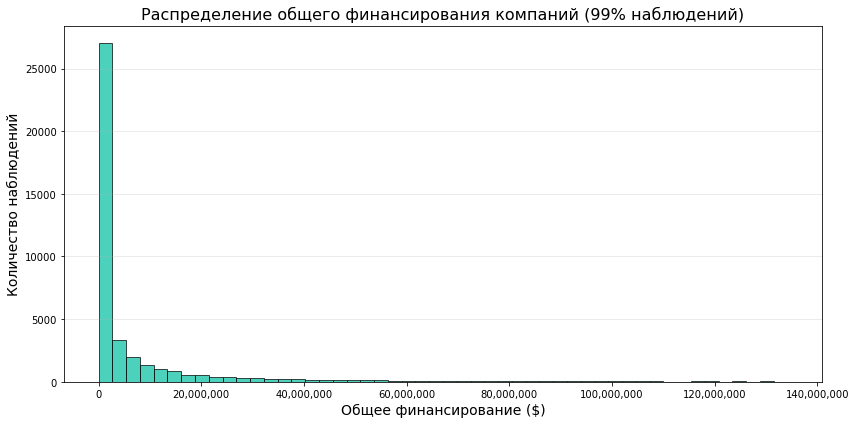

Отображено 40481 из 40890 наблюдений
Максимальное отображаемое значение: $134,192,000


In [39]:
# Оставим 99% наблюдений, исключив верхний 1% значений
threshold = companies_acquisition['funding_total'].quantile(0.99)

filtered_data = companies_acquisition.loc[
    companies_acquisition['funding_total'] <= threshold,
    'funding_total']

plt.figure(figsize=(12, 6))
plt.hist(
    filtered_data,
    bins=50,
    alpha=0.7,
    color='#00bfa0',
    edgecolor='black')

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.title('Распределение общего финансирования компаний (99% наблюдений)', fontsize=16)
plt.xlabel('Общее финансирование ($)', fontsize=14)
plt.ylabel('Количество наблюдений', fontsize=14)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Отображено {len(filtered_data)} из {len(companies_acquisition)} наблюдений')
print(f'Максимальное отображаемое значение: ${filtered_data.max():,.0f}')

In [40]:
# Рассчитаем границы выбросов по правилу 1.5 IQR
q25 = companies_acquisition['funding_total'].quantile(0.25)
q75 = companies_acquisition['funding_total'].quantile(0.75)

iqr = q75 - q25
lower_limit = q25 - 1.5 * iqr
upper_limit = q75 + 1.5 * iqr

# Для funding_total отрицательная нижняя граница практического смысла не имеет
lower_limit = max(lower_limit, 0)

outliers = companies_acquisition[
    (companies_acquisition['funding_total'] < lower_limit)
    | (companies_acquisition['funding_total'] > upper_limit)]

outliers_share = len(outliers) / len(companies_acquisition) * 100

print(f'Нижняя граница: ${lower_limit:,.0f}')
print(f'Верхняя граница: ${upper_limit:,.0f}')
print(f'Количество выбросов: {len(outliers)}')
print(f'Доля выбросов: {outliers_share:.1f}%')

Нижняя граница: $0
Верхняя граница: $14,078,300
Количество выбросов: 5889
Доля выбросов: 14.4%


Распределение общего финансирования сильно смещено вправо: медиана составляет 600 тыс. долларов, тогда как среднее превышает 10 млн долларов. Поэтому медиана лучше отражает типичный объем финансирования компании в рассматриваемой выборке.

По правилу 1.5 IQR верхняя граница составляет около 14.1 млн долларов. Выше этой границы находится 5 889 наблюдений, или 14.4% выборки. Эти значения заметно отличаются от основной части распределения, но не обязательно являются ошибками: крупные объемы финансирования могут быть реальными для отдельных компаний.

Поэтому удалять такие значения из исходных данных не будем. При дальнейшем анализе будем учитывать сильную правостороннюю асимметрию распределения и при необходимости использовать показатели, устойчивые к выбросам.

<a id="section-3-3"></a>
### 3.3. Анализ сделок с нулевой стоимостью

Отдельный интерес для заказчика представляют компании, которые были проданы за 0 или 1 доллар, несмотря на наличие ненулевого объема привлеченного финансирования.

Рассмотрим такие сделки отдельно и оценим распределение `funding_total`. С помощью межквартильного размаха определим границы выбросов и проверим, каким процентилям они соответствуют.

In [41]:
# Отберем сделки стоимостью 0 или 1 доллар для компаний с ненулевым финансированием
ca_filtered = companies_acquisition[
    (companies_acquisition['price_amount'].isin([0, 1]))
    & (companies_acquisition['funding_total'] > 0)
].copy()

print(f'Количество найденных сделок: {len(ca_filtered)}')

Количество найденных сделок: 1618


In [42]:
# Рассчитаем границы выбросов по правилу 1.5 IQR
q1 = ca_filtered['funding_total'].quantile(0.25)
q3 = ca_filtered['funding_total'].quantile(0.75)

iqr = q3 - q1
lower_limit = max(q1 - 1.5 * iqr, 0)
upper_limit = q3 + 1.5 * iqr

# Определим, каким процентилям соответствуют полученные границы
lower_percentile = (
    ca_filtered['funding_total'] <= lower_limit
).mean() * 100

upper_percentile = (
    ca_filtered['funding_total'] <= upper_limit
).mean() * 100

print(f'Нижняя граница: ${lower_limit:,.0f}')
print(f'Соответствующий процентиль: {lower_percentile:.1f}%')

print(f'Верхняя граница: ${upper_limit:,.0f}')
print(f'Соответствующий процентиль: {upper_percentile:.1f}%')
print(f'Доля наблюдений выше верхней границы: {100 - upper_percentile:.1f}%')

Нижняя граница: $0
Соответствующий процентиль: 0.0%
Верхняя граница: $35,750,000
Соответствующий процентиль: 90.9%
Доля наблюдений выше верхней границы: 9.1%


В выборке найдено 1 618 сделок стоимостью 0 или 1 доллар, при которых компания ранее привлекала ненулевое финансирование.

По правилу 1.5 IQR верхняя граница для `funding_total` составляет 35.75 млн долларов. Около 90.9% наблюдений находятся ниже этой границы, а оставшиеся 9.1% статистически выделяются относительно основной части распределения.

При этом высокая сумма привлеченного финансирования сама по себе не означает ошибку в данных. Нулевая стоимость сделки также может иметь разные причины, поэтому без дополнительной информации о конкретных сделках нельзя сделать вывод о том, почему компания с привлеченным финансированием была продана за 0 или 1 доллар.

<a id="section-3-4"></a>
### 3.4. Анализ стоимости стартапов по категориям

Заказчика интересуют категории стартапов с высокими типичными ценами покупки, а также категории с большим разбросом стоимости сделок. Такие показатели позволяют сравнить категории с разным уровнем цен и вариативностью результатов.

Для анализа определим типичную стоимость сделки и разброс цен по каждой категории. Дополнительно учтем количество сделок, чтобы отдельные категории с небольшим числом наблюдений не оказывались в лидерах только за счет нескольких крупных сделок.

Для анализа оставим сделки с известной категорией компании и положительной стоимостью покупки.

In [43]:
# Оставим сделки с положительной стоимостью и известной категорией компании
category_filtered = companies_acquisition[
    (companies_acquisition['price_amount'].notna())
    & (companies_acquisition['price_amount'] > 0)
    & (companies_acquisition['category_code'].notna())
].copy()

print(f'Количество сделок для анализа: {len(category_filtered)}')

Количество сделок для анализа: 1998


Далее определим, какую меру центральной тенденции будет разумнее всего использовать, для этого стоит ознакомиться с главными статистиками и распределением значений столбца `price_amount`, чтобы определить, чем мы будем апеллировать при выявлении типичных значений цен за стартап в разрезе категорий.

In [44]:
# Посмотрим на основные статистики стоимости сделок
cf_values = category_filtered['price_amount']

price_amount_stats = pd.DataFrame({
    'Count': [cf_values.count()],
    'Mean': [cf_values.mean()],
    'Std': [cf_values.std()],
    'Min': [cf_values.min()],
    '25%': [cf_values.quantile(0.25)],
    '50%': [cf_values.quantile(0.5)],
    '75%': [cf_values.quantile(0.75)],
    'Max': [cf_values.max()]
}, index=['Statistics'])

display(price_amount_stats)

,Count,Mean,Std,Min,25%,50%,75%,Max
Statistics,1998,1791410479,58185298221,1,20000000,73785000,307750000,2600000000000


Распределение стоимости сделок сильно смещено вправо. Медианная стоимость составляет около 73.8 млн долларов, тогда как средняя — около 1.79 млрд долларов. Максимальная стоимость сделки достигает 2.6 трлн долларов.

Такая разница между медианой и средним связана с отдельными очень крупными сделками. Поэтому для оценки типичной стоимости стартапа будем использовать медиану, которая менее чувствительна к экстремальным значениям. Для оценки разброса стоимости внутри категорий дополнительно рассчитаем стандартное отклонение.

In [45]:
# Рассчитаем медиану, СКО стоимости и количество сделок по категориям
category_stats_table = (
    category_filtered
    .groupby('category_code')['price_amount']
    .agg(['median', 'std', 'count']))

category_stats_table.columns = ['Медиана', 'СКО', 'Кол-во сделок']
category_stats_table.index.name = 'Категория компании'

Категории с небольшим количеством сделок могут показывать высокую медианную стоимость или большой разброс из-за нескольких отдельных наблюдений. Поэтому перед составлением рейтинга посмотрим на распределение количества сделок по категориям и выберем минимальный порог для включения категории в сравнение.

In [46]:
# Выведем информацию о статистиках кол-ва сделок
cst_values = category_stats_table['Кол-во сделок']
deals_stats = pd.DataFrame({
    'Count': [cst_values.count()],
    'Mean': [cst_values.mean()],
    'Std': [cst_values.std()],
    'Min': [cst_values.min()],
    '25%': [cst_values.quantile(0.25)],
    '50%': [cst_values.quantile(0.5)],
    '75%': [cst_values.quantile(0.75)],
    'Max': [cst_values.max()]
}, index=['Statistics'])
display(deals_stats.round())

,Count,Mean,Std,Min,25%,50%,75%,Max
Statistics,37,54,86,1,4,19,74,403


Медианное количество сделок по категории составляет 19. В качестве порога возьмем 20 сделок — значение, близкое к медиане распределения. Это позволит исключить категории с небольшим количеством наблюдений и при этом сохранить достаточное число категорий для сравнения.

In [47]:
# Оставим категории как минимум с 20 сделками
category_stats_table = category_stats_table[
    category_stats_table['Кол-во сделок'] >= 20]

Составим два топ-10: первый — по медианной стоимости сделки, второй — по стандартному отклонению стоимости. Десять категорий позволяют показать лидеров по каждому показателю и при этом не перегружать сравнение.

В таблицах также оставим количество сделок, чтобы при интерпретации результатов учитывать объем данных по каждой категории.

In [48]:
# Выведем 2 таблицы с топ-10, отфильтрованные по медиане и СКО
print('_'*54)
display(Markdown('**Топ-10 категорий с типично высокими ценами (по медиане)**'))
display(category_stats_table.sort_values(by='Медиана', ascending=False).head(10))
print('\n\n')
print('_'*51)
display(Markdown('**Топ-10 категорий с наибольшим разбросом цен (по СКО)**'))
display(category_stats_table.sort_values(by='СКО', ascending=False).head(10))

______________________________________________________


**Топ-10 категорий с типично высокими ценами (по медиане)**

,Медиана,СКО,Кол-во сделок
Категория компании,,,
manufacturing,351000000,1060434506,21
biotech,200000000,1968195264,263
cleantech,185000000,874419628,39
finance,171500000,1052920129,20
security,164500000,1378442023,36
ecommerce,157500000,281425549,50
public_relations,110000000,6854337756,74
network_hosting,102500000,676956798,64
semiconductor,100000000,1122024808,71





___________________________________________________


**Топ-10 категорий с наибольшим разбросом цен (по СКО)**

,Медиана,СКО,Кол-во сделок
Категория компании,,,
enterprise,54750000,241358098251,116
public_relations,110000000,6854337756,74
other,71550000,2060860617,84
biotech,200000000,1968195264,263
games_video,58250000,1463477654,88
security,164500000,1378442023,36
mobile,56000000,1319471637,117
software,48140000,1204058888,403
semiconductor,100000000,1122024808,71


По медианной стоимости сделки лидируют **Manufacturing** (351 млн долларов), **Biotech** (200 млн), **Cleantech** (185 млн), **Finance** (171.5 млн) и **Security** (164.5 млн).

Наибольший разброс стоимости сделок наблюдается в категориях **Enterprise**, **Public Relations**, **Other**, **Biotech** и **Games_video**. При этом **Biotech** входит в оба топа: категория отличается как высокой типичной стоимостью сделки, так и большим разбросом цен.

Отдельно выделяется **Enterprise**, где стандартное отклонение составляет около 241 млрд долларов и примерно в 35 раз превышает показатель следующей категории. Такое значение может быть связано с отдельными крайне крупными сделками, поэтому интерпретировать СКО этой категории нужно с осторожностью.

<a id="section-3-5"></a>
### 3.5. Анализ количества раундов финансирования

Заказчика интересует, сколько раундов финансирования обычно проходят компании с разным статусом.

Рассмотрим распределение `funding_rounds`, а затем сравним среднее и медианное количество раундов для компаний со статусами `operating`, `acquired`, `closed` и `ipo`.

In [49]:
# Посмотрим на основные статистики количества раундов финансирования
fr_values = companies_acquisition['funding_rounds']

funding_rounds_stats = pd.DataFrame({
    'Count': [fr_values.count()],
    'Mean': [fr_values.mean()],
    'Std': [fr_values.std()],
    'Min': [fr_values.min()],
    '25%': [fr_values.quantile(0.25)],
    '50%': [fr_values.quantile(0.5)],
    '75%': [fr_values.quantile(0.75)],
    'Max': [fr_values.max()]
}, index=['Statistics'])

display(funding_rounds_stats.round())

,Count,Mean,Std,Min,25%,50%,75%,Max
Statistics,40890,1,1,0,1,1,2,15


In [50]:
# Рассчитаем показатели количества раундов в разрезе статусов компаний
rounds_by_status = (
    companies_acquisition
    .groupby('status')['funding_rounds']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max']))

rounds_by_status.columns = [
    'Кол-во компаний',
    'Среднее',
    'Медиана',
    'СКО',
    'Минимум',
    'Максимум']

rounds_by_status.index.name = 'Статус компании'

display(rounds_by_status.sort_values('Медиана', ascending=False))

,Кол-во компаний,Среднее,Медиана,СКО,Минимум,Максимум
Статус компании,,,,,,
closed,2092,1,1,1,0,8
ipo,640,2,1,2,0,13
operating,28621,2,1,1,0,15
acquired,9537,1,0,1,0,12


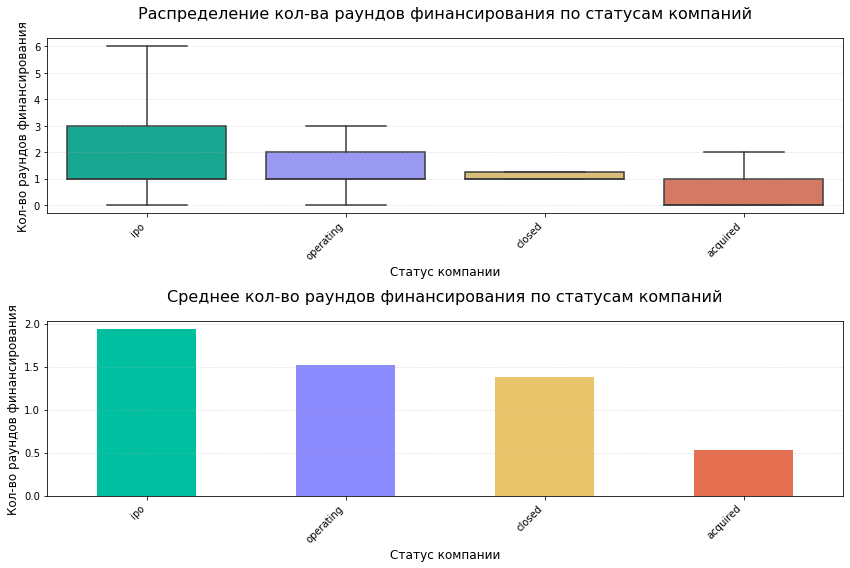

In [51]:
# Построим ящики с усами для каждого статуса компании, чтобы сравнить размах значений кол-ва раундов финансирования
plt.figure(figsize=(12, 8))
medians = companies_acquisition.groupby('status')['funding_rounds'].mean()
sorted_statuses = medians.sort_values(ascending=False).index.tolist()
colors = ['#00bfa0', '#8b8bff', '#e9c46a', '#e76f51']
plt.subplot(2, 1, 1)
sns.boxplot(data=companies_acquisition, x='status', y='funding_rounds', showfliers=False, palette=colors, order=sorted_statuses)
plt.title('Распределение кол-ва раундов финансирования по статусам компаний', fontsize=16, pad=20)
plt.ylabel('Кол-во раундов финансирования', fontsize=12)
plt.xlabel('Статус компании', fontsize=12)
plt.xticks(rotation=45, ha='right') 
plt.grid(axis='y', alpha=0.3, linestyle='--')

# Построим столбчатую диаграмму среднего кол-ва раундов финансирования в разрезе статусов компании
plt.subplot(2, 1, 2)
status_means = companies_acquisition.groupby('status')['funding_rounds'].mean().sort_values(ascending=False)
status_means.plot(kind='bar', color=['#00bfa0', '#8b8bff', '#e9c46a', '#e76f51'])
plt.title('Среднее кол-во раундов финансирования по статусам компаний', fontsize=16, pad=20)
plt.xlabel('Статус компании', fontsize=12)
plt.ylabel('Кол-во раундов финансирования', fontsize=12)
plt.xticks(rotation=45, ha='right') 
plt.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

Количество раундов финансирования в целом невелико: медиана по всей выборке составляет 1 раунд, а для 75% наблюдений количество раундов не превышает 2.

Для компаний со статусами `closed`, `ipo` и `operating` медианное количество раундов равно 1. У приобретенных компаний (`acquired`) медиана равна 0, хотя отдельные компании проходили до 12 раундов финансирования.

Наибольшее среднее количество раундов наблюдается у компаний со статусами `ipo` и `operating` — около 2. При этом различие между средним и медианой показывает, что в каждой группе есть компании с большим количеством раундов, которые повышают среднее значение.

Поэтому для описания типичной компании лучше ориентироваться на медиану: большинство компаний рассматриваемых статусов проходят небольшое количество раундов финансирования.

<a id="section-4"></a>
## 4. Итоговые выводы и рекомендации

<a id="section-4-1"></a>
### Результаты проведенного анализа

В ходе исследования были обработаны пять датасетов с информацией о компаниях, раундах финансирования, сделках по приобретению стартапов, сотрудниках и их образовании.

На этапе предобработки были проверены типы данных и пропуски, исследована возможность объединения таблиц и проанализирована структура `company_and_rounds`. Датасет был разделен на данные о компаниях и отдельных раундах финансирования, после чего была проверена связность полученных таблиц.

В исследовательской части была изучена динамика финансирования по годам, полнота данных об образовании сотрудников, распределение общего объема финансирования компаний и сделки стоимостью 0 или 1 доллар. Также были сопоставлены цены покупки стартапов разных категорий и количество раундов финансирования компаний с разными статусами.

<a id="section-4-2"></a>
### Основные выводы и ответы на исследовательские вопросы

Количество раундов финансирования заметно росло на протяжении рассматриваемого периода: с 76 в 1999 году до 11 072 в 2013 году. При этом медианный размер финансирования одного раунда после максимума в 5.5 млн долларов в 2005 году постепенно снизился до 1.2 млн долларов к 2013 году. Данные показывают одновременный рост количества раундов и снижение их типичного размера, однако определить причины этой динамики на основе имеющихся данных нельзя.

Полнота информации об образовании сотрудников различается между группами компаний, но однозначной зависимости от размера компании не наблюдается. Доля сотрудников без информации об образовании находится в диапазоне от 28.62% у крупных компаний до 53.38% у растущих компаний. При этом отсутствие информации в датасете не означает отсутствие образования у сотрудника.

Распределение общего финансирования компаний сильно смещено вправо: медиана составляет 600 тыс. долларов, а среднее превышает 10 млн долларов. По правилу 1.5 IQR значения выше 14.1 млн долларов относятся к статистическим выбросам и составляют 14.4% наблюдений, однако такие значения не обязательно являются ошибками.

Среди сделок также найдено 1 618 случаев, когда компания с ненулевым объемом привлеченного финансирования была приобретена за 0 или 1 доллар. Без дополнительной информации о конкретных сделках определить причины такой стоимости нельзя.

По медианной стоимости покупки среди рассмотренных категорий лидируют Manufacturing (351 млн долларов), Biotech (200 млн долларов) и Cleantech (185 млн долларов). Наибольший разброс стоимости сделок наблюдается в категориях Enterprise, Public Relations и Other. Biotech входит в число лидеров по обоим показателям.

Большинство компаний проходит небольшое количество раундов финансирования. Медиана по всей выборке составляет 1 раунд. Для компаний со статусами `closed`, `ipo` и `operating` медиана также равна 1, а для `acquired` — 0. При этом наибольшее среднее количество раундов наблюдается у компаний со статусами `ipo` и `operating` — около 2.

<a id="section-4-3"></a>
### Рекомендации

При дальнейшем анализе потенциальных сделок стоит отдельно рассмотреть категории Manufacturing, Biotech и Cleantech, которые показали наиболее высокую медианную стоимость покупки. При этом высокая цена сделки сама по себе не говорит о доходности или инвестиционной привлекательности категории, поэтому для принятия инвестиционных решений потребуется дополнительный анализ.

Biotech представляет отдельный интерес, поскольку входит в число лидеров как по медианной стоимости, так и по разбросу цен. Для категорий с особенно высоким разбросом, в первую очередь Enterprise, стоит дополнительно проверять отдельные крупные сделки, которые могут сильно влиять на итоговые показатели.

При сравнении компаний по объему финансирования лучше использовать медианные значения и другие устойчивые к выбросам показатели, поскольку распределение сильно смещено из-за небольшого числа очень крупных значений. Количество раундов финансирования также не стоит использовать как самостоятельный показатель успешности компании: полученные данные показывают различия между статусами, но не позволяют установить причинную связь.

При работе с данными об образовании сотрудников необходимо учитывать их неполноту во всех группах компаний и по возможности дополнять информацию из других источников.